# Setup

In [1]:
# Collab Setup
# !git clone https://github.com/fastai/course22p2.git
# %cd course22p2
# !pip install -q fastcore einops datasets timm
# import sys
# sys.path.append('/content/course22p2')
# !pip install -q k-diffusion fastcore einops datasets timm
# !pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
# !pip install -q fastcore einops datasets timm k-diffusion
# !pip install -q torcheval fastcore einops datasets timm k-diffusion
# !pip install -q numpy==1.26.4 --force-reinstall

In [2]:
# Kaggle Setup
!git clone https://github.com/fastai/course22p2.git
!pip install -q numpy --upgrade          # upgrade numpy FIRST
!pip install -q fastcore einops datasets timm k-diffusion torcheval

fatal: destination path 'course22p2' already exists and is not an empty directory.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 87.2 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
dctorch 0.1.2 requires numpy<2.0.0,>=1.22.3, but you have numpy 2.4.6 which is incompatible.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.1 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.4.6 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-c

In [3]:
# Kaggle Setup
import sys
sys.path.append('/kaggle/working/course22p2')
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0,1'

In [4]:
import timm, torch, random, datasets, math, fastcore.all as fc, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import k_diffusion as K, torchvision.transforms as T
import torchvision.transforms.functional as TF,torch.nn.functional as F

from torch.utils.data import DataLoader,default_collate
from pathlib import Path
from torch.nn import init
from fastcore.foundation import L
from torch import nn,tensor
from datasets import load_dataset
from operator import itemgetter
from torcheval.metrics import MulticlassAccuracy
from functools import partial
from torch.optim import lr_scheduler
from torch import optim

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *
from miniai.accel import *

In [5]:
from fastprogress import progress_bar
from diffusers import UNet2DModel, DDIMPipeline, DDPMPipeline, DDIMScheduler, DDPMScheduler

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


In [6]:
torch.set_printoptions(precision=5, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray_r'
mpl.rcParams['figure.dpi'] = 70

import logging
logging.disable(logging.WARNING)

set_seed(42)
if fc.defaults.cpus>8: fc.defaults.cpus=8

In [7]:
xl,yl = 'image','label'
name = "zalando-datasets/fashion_mnist" # new HF require the namespace
n_steps = 1000
bs = 512
dsd = load_dataset(name)

README.md: 0.00B [00:00, ?B/s]

fashion_mnist/train-00000-of-00001.parqu(…):   0%|          | 0.00/30.9M [00:00<?, ?B/s]

fashion_mnist/test-00000-of-00001.parque(…):   0%|          | 0.00/5.18M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [8]:
sig_data = 0.66

In [9]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))*2-1 for o in b[xl]]

def scalings(sig):
    totvar = sig**2+sig_data**2
    # c_skip,c_out,c_in
    return sig_data**2/totvar,sig*sig_data/totvar.sqrt(),1/totvar.sqrt()

def noisify(x0):
    device = x0.device
    sig = (torch.randn([len(x0)])*1.2-1.2).exp().to(x0).reshape(-1,1,1,1)
    noise = torch.randn_like(x0, device=device)
    c_skip,c_out,c_in = scalings(sig)
    noised_input = x0 + noise*sig
    target = (x0-c_skip*noised_input)/c_out
    return (noised_input*c_in,sig.squeeze()),target

def collate_ddpm(b): return noisify(default_collate(b)[xl])
def dl_ddpm(ds): return DataLoader(ds, batch_size=bs, collate_fn=collate_ddpm, num_workers=0)

In [10]:
tds = dsd.with_transform(transformi)
dls = DataLoaders(dl_ddpm(tds['train']), dl_ddpm(tds['test']))

# Train (remember this is the karras diff model)

In [11]:
# Pre-Activation conv
def unet_conv(ni, nf, ks=3, stride=1, act=nn.SiLU, norm=None, bias=True):
    layers = nn.Sequential()
    if norm: layers.append(norm(ni))
    if act : layers.append(act())
    layers.append(nn.Conv2d(ni, nf, stride=stride, kernel_size=ks, padding=ks//2, bias=bias))
    return layers

`nn.SiLU` -> is very close to `ReLU`

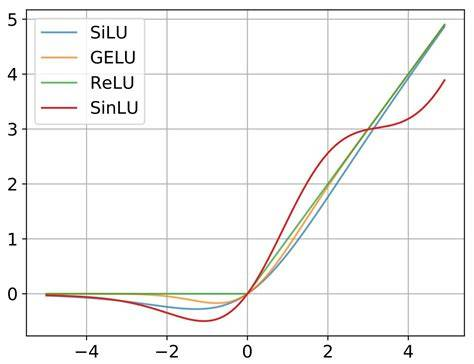
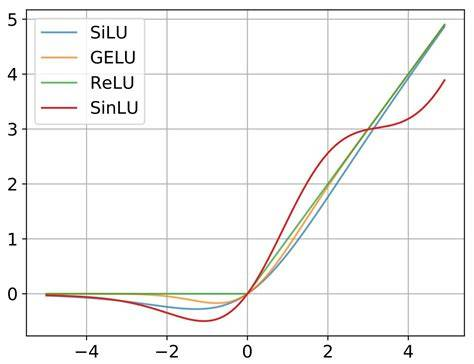

In [12]:
class UnetResBlock(nn.Module):
  def __init__(self, ni, nf=None, ks=3, act=nn.SiLU, norm=nn.BatchNorm2d):
    super().__init__()
    if nf is None: nf = ni
    self.convs = nn.Sequential(unet_conv(ni, nf, ks, act=act, norm=norm),
                               unet_conv(nf, nf, ks, act=act, norm=norm))
    self.idconv = fc.noop if ni==nf else nn.Conv2d(ni, nf, 1)

  def forward(self, x): return self.convs(x) + self.idconv(x)

In [13]:
# mixin inheritance
class A:
  def __call__(self):
    super().__call__()
    print('a')

class B:
  def __call__(self):  print('b')

class C(A,B): pass


C()()

b
a


In [14]:
class SaveModule():
  def forward(self, x, *args, **kwargs):
    self.saved = super().forward(x, *args, **kwargs)
    return self.saved

class SavedResBlock(SaveModule, UnetResBlock): pass
class SavedConv(SaveModule, nn.Conv2d): pass

In [15]:
def down_block(ni, nf, add_down=True, num_layers=1):
  res =nn.Sequential(*[SavedResBlock(ni if i==0 else nf, nf) for i in range(num_layers)])
  if add_down : res.append(SavedConv(nf, nf, kernel_size=3, stride=2, padding=1))
  return res

In [16]:
def upsample(nf): return nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv2d(nf, nf, kernel_size=3, padding=1, stride=1))

In [17]:
class UpBlock(nn.Module):
  def __init__(self, ni, prev_nf, nf, add_up=True, num_layers=2):
    super().__init__()
    self.resnets= nn.ModuleList(
        [UnetResBlock((prev_nf if i==0 else nf)+(ni if (i==num_layers-1) else nf), nf) for i in range(num_layers)])
    self.up = upsample(nf) if add_up else nn.Identity()

  def forward(self, x, ups):
    for resnet in self.resnets: x = resnet(torch.cat([x, ups.pop()], dim=1))
    return self.up(x)

- `num_layers=2` -> We always make the `num_layers` in the UpBlock +1 what is in the `Down_block` becuase in the `Down_Block` we store both the `ResNet` and `Conv` output
- So what happens is that during the `up_sampling`:
  - we concat the save `ResNet` output from `Down_sampling` for the input for one `Up_sampling` `ResNet`
  - we concat the save `Conv` output from `Down_sampling` for the input for one `Up_sampling` `ResNet`


    dim=1 = concatenate along channels

    x:          (B, 64,  32, 32)
    ups.pop():  (B, 64,  32, 32)
    cat dim=1:  (B, 128, 32, 32)   ← H,W unchanged, channels doubled

    - That is the reason for Making Addition here (for resnet to be compatible
    with features of the concatnation):
      (prev_nf if i==0 else nf)+(ni if (i==num_layers-1) else nf)

In [18]:
class UNet2DModel(nn.Module):
  def __init__(self, in_channels=3, out_channels=3, nfs=(224,448,672,896), num_layers=1):
    super().__init__()
    self.conv_in = nn.Conv2d(in_channels, nfs[0], kernel_size=3, padding=1, stride=1)
    self.downs = nn.Sequential()
    nf = nfs[0] # to make loop work
    for i in range(len(nfs)):
      ni = nf
      nf = nfs[i]
      self.downs.append(down_block(ni, nf, add_down=(i!=(len(nfs)-1)), num_layers=num_layers))
    self.mid_block = UnetResBlock(nfs[-1]) # so this is not going to change(feats,spacials)

    rev_nfs = list(reversed(nfs))
    nf = rev_nfs[0]
    self.ups = nn.ModuleList()
    for i in range(len(nfs)):
      prev_nf = nf
      nf = rev_nfs[i]
      ni = rev_nfs[min(i+1, len(nfs)-1)]
      self.ups.append(UpBlock(ni, prev_nf, nf, add_up=(i!=len(nfs)-1), num_layers=num_layers+1))
    self.conv_out = unet_conv(nfs[0], out_channels, act=nn.SiLU, norm=nn.BatchNorm2d)

  def forward(self, x):
    x = self.conv_in(x[0]) # becuase the input for diff is (noisy_image, timestep)
    saved = [x]
    x = self.downs(x)
    saved += [l.saved for b in self.downs for l in b]
    x = self.mid_block(x)
    for block in self.ups: x= block(x, saved) # we made the torch.cat,etc.. in UpBlock
    return self.conv_out(x)

`add_down=(i!=(len(nfs)-1))`, `add_up=(i!=len(nfs)-1)` -> because reaching the `Mini`, `Max` Spacial dims, so we just stop

In [19]:
k = [3,4,5,6,7]
reversed(k), list(reversed(k))

(<list_reverseiterator at 0x7982ff4c2290>, [7, 6, 5, 4, 3])

In [20]:
model = UNet2DModel(in_channels=1, out_channels=1, nfs=(32,64,128,256), num_layers=2) # smaller model for Fashion mnist

In [21]:
lr = 3e-3
epochs = 25
opt_func = partial(optim.Adam, eps=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched), MixedPrecision()]
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

In [22]:
# learn.fit(epochs)

    loss	epoch	train
    0.496	0	train
    0.338	0	eval
    0.246	1	train
    0.230	1	eval
    0.209	2	train
    0.219	2	eval
    0.194	3	train
    0.216	3	eval
    0.185	4	train
    0.222	4	eval
    0.179	5	train
    0.217	5	eval
    0.173	6	train
    0.198	6	eval
    0.169	7	train
    0.184	7	eval
    0.164	8	train
    0.203	8	eval
    0.161	9	train
    0.230	9	eval
    0.159	10	train
    0.181	10	eval
    0.156	11	train
    0.167	11	eval
    0.155	12	train
    0.190	12	eval
    0.153	13	train
    0.170	13	eval
    0.151	14	train
    0.153	14	eval
    0.150	15	train
    0.164	15	eval
    0.149	16	train
    0.155	16	eval
    0.147	17	train
    0.149	17	eval
    0.146	18	train
    0.147	18	eval
    0.145	19	train
    0.145	19	eval
    0.144	20	train
    0.143	20	eval
    0.143	21	train
    0.142	21	eval
    0.142	22	train
    0.144	22	eval
    0.142	23	train
    0.143	23	eval
    0.142	24	train
    0.142	24	eval


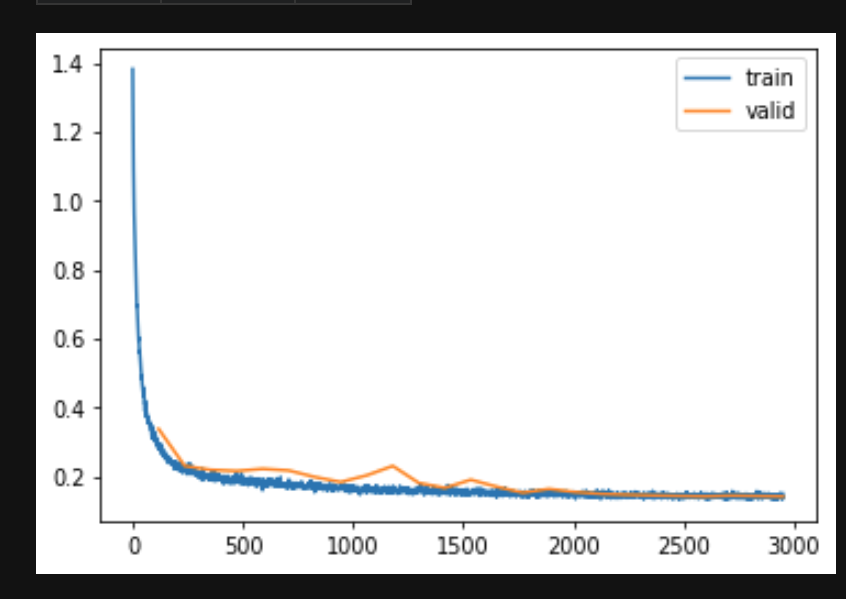


# TimeSteps Embedding

- Encode scalar `t` into a vector so model can identify any timestep

In [23]:
emb_dim = 16
tsteps = torch.linspace(-10,10,100)
max_period = 10000

    max_period=10000 → slowest frequency completes 1 cycle every 10000 steps
      with 1000 timesteps → never repeats → unique at every scale
      intentional overkill for safety

    timestep values (integers, alphabar, linspace) → doesn't matter
      model normalizes and learns to interpret whatever scalar you give it
      embedding just ensures: close t → similar vector, far t → different vector

In [24]:
math.log(10000), math.log(1000)

(9.210340371976184, 6.907755278982137)

In [25]:
exponent = -math.log(max_period) * torch.linspace(0, 1, emb_dim//2, device=tsteps.device)

- `torch.linspace(0, 1, emb_dim//2, device=tsteps.device)` :
  - `emb_dim//2` in linspace → because `sin+cos` doubles it back to emb_dim later

  - `8 frequencies` per timestep → `8 different "lenses"` to view `same t`
  - `each frequency` = `one feature` dimension at a different scale
  - `all frequencies combined` → unique ID per timestep

    log-spaced frequencies → covers all scales simultaneously
      linear: 1.0, 0.875, 0.75...   equal gaps, misses small scales
      log:    1.0, 0.1,   0.01...   equal ratios, covers everything
      like a clock: seconds=high freq, hours=low freq, need both for exact time

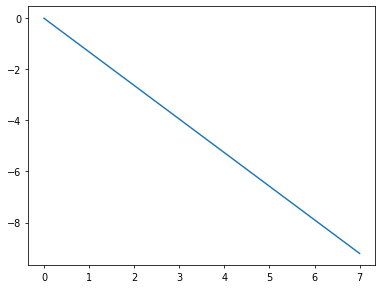

In [26]:
plt.plot(exponent)

In [27]:
tsteps.shape, exponent.shape

(torch.Size([100]), torch.Size([8]))

In [28]:
emb = tsteps[:,None].float() * exponent.exp()[None,:] # all frequency combinations for each t
emb.shape

torch.Size([100, 8])

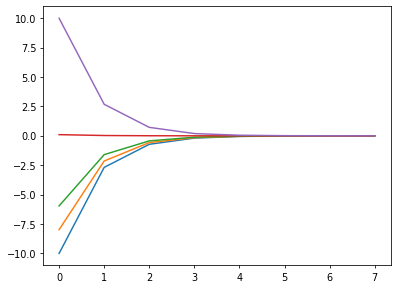

In [29]:
plt.plot(emb[0])
plt.plot(emb[10])
plt.plot(emb[20])
plt.plot(emb[50])
plt.plot(emb[-1]);

In [30]:
emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)
emb.shape # emb_dim we set earlier

torch.Size([100, 16])

    sin+cos (not just sin) → uniqueness within one cycle
      sin alone: 0° and 180° both = 0, collision
      cos alone: 90° and 270° both = 0, collision
      pair (sin,cos): every angle gives unique point on unit circle, no collision

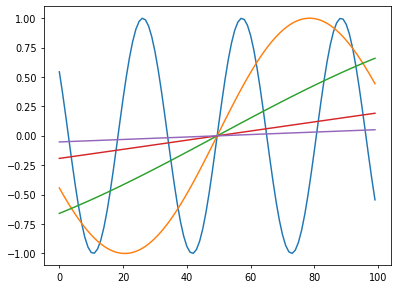

In [31]:
plt.plot(emb[:,0])
plt.plot(emb[:,1])
plt.plot(emb[:,2])
plt.plot(emb[:,3])
plt.plot(emb[:,4]);

That is the diff `wave_length` for each `Sin_wave` features[8] -> (here it is 0->4), so that is all to make the `embeding_features` of the `t` more rich

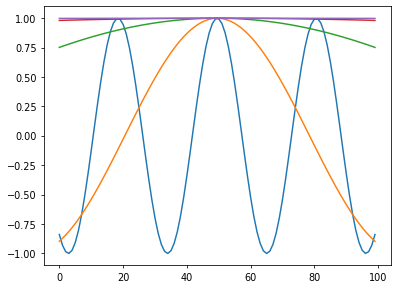

In [32]:
plt.plot(emb[:,8])
plt.plot(emb[:,9])
plt.plot(emb[:,10])
plt.plot(emb[:,11])
plt.plot(emb[:,12]);

Same for `Cos`

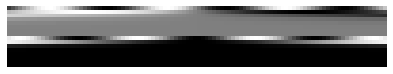

In [33]:
show_image(emb.T, figsize=(7,7));

  - `each column` = `full embedding `for one timestep   
  - `each row`    = `one feature` across all timesteps  

  - `top half of image`    (rows 0-7)  = `sin features`
  - `bottom half of image` (rows 8-15) = `cos features`

In [34]:
def timestep_embedding(tsteps, emb_dim, max_period= 10000):
    exponent = -math.log(max_period) * torch.linspace(0, 1, emb_dim//2, device=tsteps.device)
    emb = tsteps[:,None].float() * exponent.exp()[None,:]
    emb = torch.cat([emb.sin(), emb.cos()], dim=-1)
    return F.pad(emb, (0,1,0,0)) if emb_dim%2==1 else emb # don't worry about the padding thing

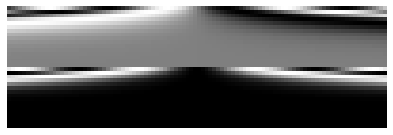

In [35]:
show_image(timestep_embedding(tsteps, 32, max_period=1000).T, figsize=(7,7));

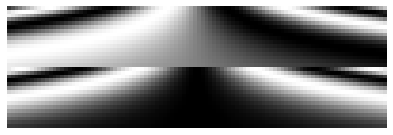

In [36]:
show_image(timestep_embedding(tsteps, 32, max_period=10).T, figsize=(7,7));

# TimeSteps Embeding Unet

In [37]:
from functools import wraps

In [38]:
def lin(ni, nf, act=nn.SiLU, norm=None, bias=True):
  layers = nn.Sequential()
  if norm : layers.append(norm(ni)) 
  if act : layers.append(act())
  layers.append(nn.Linear(ni, nf, bias=bias))
  return layers

`norm(ni) — why pass ni` -> `BatchNorm1d(ni)` creates learnable gamma/beta of size ni
  it needs to know how many features to normalize

In [39]:
class EmbResBlock(nn.Module):
  def __init__(self, n_emb, ni, nf=None, act=nn.SiLU, norm=nn.BatchNorm2d):
    super().__init__()
    if nf is None : nf = ni
    self.lin_emb = nn.Linear(n_emb, nf*2) # *2 bec we make chunk later
    self.conv1 = unet_conv(ni, nf, act=act, norm=norm)
    self.conv2 = unet_conv(nf, nf, act=act, norm=norm)
    self.idconv = fc.noop if ni==nf else nn.Conv2d(ni, nf, kernel_size=1)

  def forward(self, x, t):
    inp = x
    t_emb = self.lin_emb(F.silu(t))[:, :, None, None] # expand to have H,W dims    WHYT PASS IN SELUI
    x = self.conv1(x)
    scale, shift = torch.chunk(t_emb, 2, dim=1) # at feats dim, bec as prev we made *2 in lin
    x = x*(1+scale) + shift
    x = self.conv2(x)
    return x + self.idconv(inp)

- At ` t_emb` here -> there is no problem of applying activation because this is not the raw `t_emb` -> this the output of the `t_emb_MLP` layer
- Why `1+scale` — why not just `scale` :
  
      - at init weights ≈ 0 → scale ≈ 0 → x*(1+0) = x → identity
      - without +1: scale≈0 → x*0 = 0 → kills entire signal at start
      

In [40]:
# save using new cleaner method work with any layer
def saved(block, obj):
  block_ = block.forward

  @wraps(block.forward)
  def _f(*args, **kwargs):
    res = block_(*args, **kwargs)
    obj.saved.append(res)
    return res

  block.forward = _f
  return block

 - You CAN just do `block.forward = _f` `without @wraps` -> `@wraps` only preserves metadata (function name, docstring) for debugging -> `code cleanliness convention`

In [41]:
class DownBlock(nn.Module):
  def __init__(self, n_emb, ni, nf, add_down=True, num_layers=1):
    super().__init__()
    self.resnets = nn.ModuleList([saved(EmbResBlock(n_emb, ni if i==0 else nf, nf), self) for i in range(num_layers)])
    self.down = saved(nn.Conv2d(nf, nf, 3, stride=2, padding=1), self) if add_down else nn.Identity()

  def forward(self, x, t):
    self.saved = []
    for res in self.resnets : x = res(x, t)
    return self.down(x)

We have to make is as ` nn.ModuleList()` because  `nn.Sequential()` Can't take 2 inputs

In [42]:
class UpBlock(nn.Module):
  def __init__(self, n_emb, ni, prev_nf, nf, add_up=True, num_layers=2):
    super().__init__()
    self.resnets = nn.ModuleList([EmbResBlock(n_emb, (prev_nf if i==0 else nf)+(ni if (i==num_layers-1) else nf), nf) for i in range(num_layers)])
    self.up = upsample(nf) if add_up else nn.Identity()

  def forward(self, x, t, ups):
    for resnet in self.resnets: x = resnet(torch.cat([x, ups.pop()], dim=1), t)
    return self.up(x)

In [43]:
class EmbUNetModel(nn.Module):
  def __init__(self, in_channels=3, out_channels=3, nfs=(224,448,672,896), num_layers=1):
    super().__init__()
    self.conv_in = nn.Conv2d(in_channels, nfs[0], kernel_size=3, padding=1) # Same spacial
    self.n_temb = nf = nfs[0]
    n_emb = nf*4
    self.emb_mlp = nn.Sequential(lin(self.n_temb, n_emb, norm=nn.BatchNorm1d), # leaving the activation here made all the diff
                                 lin(n_emb, n_emb))
    self.downs = nn.ModuleList()
    for i in range(len(nfs)):
      ni = nf
      nf = nfs[i]
      self.downs.append(DownBlock(n_emb, ni, nf, add_down=(i!=(len(nfs)-1)), num_layers = num_layers))
    self.mid_block = EmbResBlock(n_emb, nfs[-1])

    rev_nfs = list(reversed(nfs))
    nf = rev_nfs[0]
    self.ups = nn.ModuleList()
    for i in range(len(nfs)):
      prev_nf = nf
      nf = rev_nfs[i]
      ni = rev_nfs[min(i+1, len(nfs)-1)]
      self.ups.append(UpBlock(n_emb, ni, prev_nf, nf, add_up= (i!=(len(nfs)-1)), num_layers=num_layers+1))
    self.conv_out = unet_conv(nfs[0], out_channels, act=nn.SiLU, norm=nn.BatchNorm2d, bias=False)   # bias = False, bec BatchNorm

  def forward(self, inp):
    x, t = inp
    temb = timestep_embedding(t, self.n_temb)
    emb = self.emb_mlp(temb)
    x = self.conv_in(x)
    saved = [x]
    for block in self.downs: x = block(x, emb)
    saved += [p for b in self.downs for p in b.saved]
    x = self.mid_block(x, emb)
    for block in self.ups: x = block(x, emb, saved)
    return self.conv_out(x)

At `self.emb_mlp = nn.Sequential(lin(self.n_temb, n_emb, norm=nn.BatchNorm1d),` # leaving the `activation` here made all the diff without it there was NAN sometimes in eval during training and the preds were exploding , it can be float16 overflow with batch normalization or also reduced MLP expressiveness from act=None. but what we know is activation made it better

In [44]:
model = EmbUNetModel(in_channels=1, out_channels=1, nfs=(32,64,128,256), num_layers=2)

In [45]:
lr = 1e-2
epochs = 25
opt_func = partial(optim.Adam, eps=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched), MixedPrecision()]
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

/kaggle/working/course22p2/miniai/accel.py:33: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  def before_fit(self, learn): self.scaler = torch.cuda.amp.GradScaler()


loss,epoch,train
0.380,0,train
0.260,0,eval
0.216,1,train
0.235,1,eval
0.192,2,train
0.226,2,eval
0.180,3,train
0.224,3,eval
0.172,4,train
0.209,4,eval


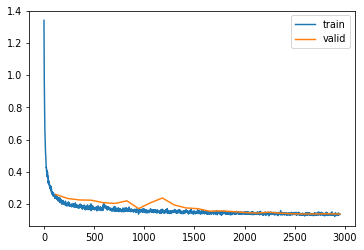

In [46]:
learn.fit(epochs)

# Sampling

In [59]:
from miniai.fid import ImageEval

cmodel = torch.load('/kaggle/input/models/seif222/data-aug2/pytorch/default/1/data_aug2.pkl', weights_only=False)
del(cmodel[8])
del(cmodel[7])

bs = 2048
tds2 = dsd.with_transform(transformi)
dls2 = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

dt = dls2.train
xb,yb = next(iter(dt))

ie = ImageEval(cmodel, dls2, cbs=[DeviceCB()])

In [60]:
sz = (2048,1,32,32)

In [61]:
def sigmas_karras(n, sigma_min=0.01, sigma_max=80., rho=7.):
    ramp = torch.linspace(0, 1, n)
    min_inv_rho = sigma_min**(1/rho)
    max_inv_rho = sigma_max**(1/rho)
    sigmas = (max_inv_rho + ramp * (min_inv_rho-max_inv_rho))**rho
    return torch.cat([sigmas, tensor([0.])]).cuda()

def denoise(model, x, sig):
    sig = sig[None] #* torch.ones((len(x),1), device=x.device)
    c_skip,c_out,c_in = scalings(sig)
    return model((x*c_in, sig))*c_out + x*c_skip

def get_ancestral_step(sigma_from, sigma_to, eta=1.):
    if not eta: return sigma_to, 0.
    var_to,var_from = sigma_to**2,sigma_from**2
    sigma_up = min(sigma_to, eta * (var_to * (var_from-var_to)/var_from)**0.5)
    return (var_to-sigma_up**2)**0.5, sigma_up

@torch.no_grad()
def sample_euler_ancestral(x, sigs, i, model, eta=1.):
    sig,sig2 = sigs[i],sigs[i+1]
    denoised = denoise(model, x, sig)
    sigma_down,sigma_up = get_ancestral_step(sig, sig2, eta=eta)
    x = x + (x-denoised)/sig*(sigma_down-sig)
    return x + torch.randn_like(x)*sigma_up

@torch.no_grad()
def sample_euler(x, sigs, i, model):
    sig,sig2 = sigs[i],sigs[i+1]
    denoised = denoise(model, x, sig)
    return x + (x-denoised)/sig*(sig2-sig)

@torch.no_grad()
def sample_heun(x, sigs, i, model, s_churn=0., s_tmin=0., s_tmax=float('inf'), s_noise=1.):
    sig,sig2 = sigs[i],sigs[i+1]
    n = len(sigs)
    gamma = min(s_churn/(n-1), 2**0.5-1) if s_tmin<=sig<=s_tmax else 0.
    eps = torch.randn_like(x) * s_noise
    sigma_hat = sig * (gamma+1)
    if gamma > 0: x = x + eps * (sigma_hat**2-sig**2)**0.5
    denoised = denoise(model, x, sig)
    d = (x-denoised)/sig
    dt = sig2-sigma_hat
    x_2 = x + d*dt
    if sig2==0: return x_2
    denoised_2 = denoise(model, x_2, sig2)
    d_2 = (x_2-denoised_2)/sig2
    d_prime = (d+d_2)/2
    return x + d_prime*dt

def sample(sampler, model, steps=100, sigma_max=80., **kwargs):
    preds = []
    x = torch.randn(sz).cuda()*sigma_max
    sigs = sigmas_karras(steps, sigma_max=sigma_max)
    for i in progress_bar(range(len(sigs)-1)):
        x = sampler(x, sigs, i, model, **kwargs)
        preds.append(x)
    return preds

In [62]:
preds = sample(sample_euler_ancestral, model, steps=100, eta=1.)

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:16&lt;00:00]</div>

In [63]:
s = preds[-1]
s.min(),s.max()

(tensor(-1.07259, device='cuda:0'), tensor(1.43163, device='cuda:0'))

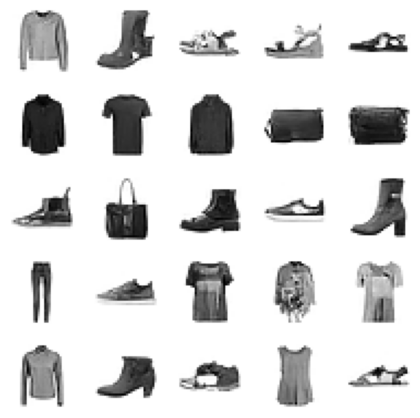

In [64]:
show_images(s[:25].clamp(-1,1), imsize=1.5)

In [65]:
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)} \n {s.shape}')

(21.100830078125, 0.5033481121063232) 
 (2.126708984375, -0.10133720189332962) 
 torch.Size([2048, 1, 32, 32])


In [66]:
preds = sample(sample_euler, model, steps=100)
s = preds[-1]
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)} \n {s.shape}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:22&lt;00:00]</div>

(21.294921875, 0.3404967486858368) 
 (2.126708984375, -0.10133720189332962) 
 torch.Size([2048, 1, 32, 32])


In [67]:
preds = sample(sample_heun, model, steps=20, s_churn=0.5)
s = preds[-1]
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)} \n {s.shape}')

<div><progress max="20" value="20"></progress> 100.00% [20/20 00:32&lt;00:00]</div>

(22.262451171875, 0.4309043288230896) 
 (2.126708984375, -0.10133720189332962) 
 torch.Size([2048, 1, 32, 32])


In [68]:
from scipy import integrate

def linear_multistep_coeff(order, t, i, j):
    if order-1 > i: raise ValueError(f'Order {order} too high for step {i}')
    def fn(tau):
        prod = 1.
        for k in range(order):
            if j == k: continue
            prod *= (tau-t[i-k]) / (t[i-j]-t[i-k])
        return prod
    return integrate.quad(fn, t[i], t[i+1], epsrel=1e-4)[0]

@torch.no_grad()
def sample_lms(model, steps=100, order=4, sigma_max=80.):
    preds = []
    x = torch.randn(sz).cuda()*sigma_max
    sigs = sigmas_karras(steps, sigma_max=sigma_max)
    ds = []
    for i in progress_bar(range(len(sigs)-1)):
        sig = sigs[i]
        denoised = denoise(model, x, sig)
        d = (x-denoised)/sig
        ds.append(d)
        if len(ds) > order: ds.pop(0)
        cur_order = min(i+1, order)
        coeffs = [linear_multistep_coeff(cur_order, sigs, i, j) for j in range(cur_order)]
        x = x + sum(coeff*d for coeff, d in zip(coeffs, reversed(ds)))
        preds.append(x)
    return preds

In [69]:
preds = sample_lms(model, steps=50, order=3)
s = preds[-1]
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)} \n {s.shape}')

<div><progress max="50" value="50"></progress> 100.00% [50/50 00:42&lt;00:00]</div>

(21.983154296875, 0.18336017429828644) 
 (2.126708984375, -0.10133720189332962) 
 torch.Size([2048, 1, 32, 32])


In [70]:
preds = sample_lms(model, steps=20, order=3)
s = preds[-1]
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)} \n {s.shape}')

<div><progress max="20" value="20"></progress> 100.00% [20/20 00:16&lt;00:00]</div>

(16.826904296875, 0.24775682389736176) 
 (2.126708984375, -0.10133720189332962) 
 torch.Size([2048, 1, 32, 32])


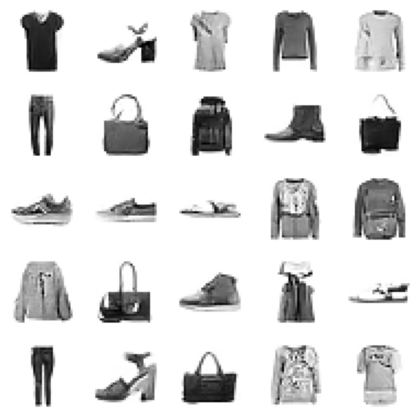

In [71]:
show_images(s[:25].clamp(-1,1), imsize=1.5)